## Welcome and learning objectives

**Goal:** learn Pandas and data visualization from absolute basics to advanced descriptive analysis, using actual Olist data. Run cells **in order**. Each section answers a real question. Data is not included in this repository; follow `data/README.md`. All amounts are in Brazilian reais (BRL).

## 0. Setup and imports

Import the packages and locate the project root. This works when launching Jupyter from either the repository root or the `notebooks` folder.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [2]:


# Detect project directory automatically
current_dir = Path.cwd().resolve()

if (current_dir / "src").is_dir():
    PROJECT_ROOT = current_dir

elif (current_dir.parent / "src").is_dir():
    PROJECT_ROOT = current_dir.parent

else:
    raise FileNotFoundError(
        "Project directory not found."
    )

# Create output directories
for folder in ["figures", "results"]:
    (PROJECT_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project root:", PROJECT_ROOT)


Project root: C:\Users\Alireza\Desktop\ameli\olist-pandas-github


In [3]:



if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src").is_dir(), "Start Jupyter from the repository root or notebooks/."
sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = PROJECT_ROOT / "data"
from src.data_cleaning import load_tables, quality_report, order_level_items
from src.exploratory_analysis import seller_summary, category_summary, monthly_item_values
from src.visualization import price_histogram, monthly_line
from src.pricing_analysis import multi_seller_product_spreads, product_month_price_comparison
print("Data folder:", DATA_DIR)

Data folder: C:\Users\Alireza\Desktop\ameli\olist-pandas-github\data


## 1. Load real CSV files

`pd.read_csv` loads one CSV into a **DataFrame** (a table). The helper loads all nine files and converts order-date columns to datetime. If files are missing, follow the instructions in `data/README.md`.

In [4]:
tables = load_tables(DATA_DIR)
items = tables["items"]
orders = tables["orders"]
print("Order-item rows:", len(items))
display(items.head(5))

Order-item rows: 112650


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


## 2. First look at a table

`head(n)` returns the first n rows; `tail(n)` returns the last n rows. They do not change your data.

In [5]:
display(items.head(3))
display(items.tail(3))

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72
112649,fffe41c64501cc87c801fd61db3f6244,1,350688d9dc1e75ff97be326363655e01,f7ccf836d21b2fb1de37564105216cc1,2018-06-12 17:10:13,43.00,12.79


## 3. Rows, columns and types

`.shape` is `(rows, columns)`; `.columns` lists names; `.dtypes` shows each column type.

In [6]:
print("Shape:", items.shape)
print("Columns:", items.columns.tolist())
print("Types:")
print(items.dtypes)

Shape: (112650, 7)
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Types:
order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipping_limit_date    datetime64[ns]
price                         float64
freight_value                 float64
dtype: object


## 4. Select one or more columns

Use one pair of brackets for a **Series**, or double brackets for a **DataFrame**.

In [7]:
display(items["price"].head())
display(items[["price", "freight_value"]].head())

0     58.90
1    239.90
2    199.00
3     12.99
4    199.90
Name: price, dtype: float64

,price,freight_value
0,58.90,13.29
1,239.90,19.93
2,199.00,17.87
3,12.99,12.79
4,199.90,18.14


## 5. Basic descriptive statistics

Learn `mean`, `median`, `min`, `max`, `sum`, and `describe`.

In [8]:
print("Mean:", items["price"].mean())
print("Median:", items["price"].median())
print("Min/Max:", items["price"].min(), items["price"].max())
print("Sum:", items["price"].sum())
display(items["price"].describe())

Mean: 120.65373901464713
Median: 74.99
Min/Max: 0.85 6735.0
Sum: 13591643.7


count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

## 6. Select rows by position and label

`iloc` uses integer positions; `loc` uses row labels and column names.

In [9]:
display(items.iloc[:5, :3])
display(items.loc[:4, ["product_id", "price"]])

,order_id,order_item_id,product_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089


,product_id,price
0,4244733e06e7ecb4970a6e2683c13e61,58.90
1,e5f2d52b802189ee658865ca93d83a8f,239.90
2,c777355d18b72b67abbeef9df44fd0fd,199.00
3,7634da152a4610f1595efa32f14722fc,12.99
4,ac6c3623068f30de03045865e4e10089,199.90


## 7. Filter the data

A Boolean condition selects rows meeting the criterion. Add parentheses around multiple conditions.

In [10]:
expensive = items.loc[items["price"] > 200]
print("Items above BRL 200:", len(expensive))
display(items.loc[(items["price"] > 200) & (items["freight_value"] < 20)].head())

Items above BRL 200: 13374


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
16,0009c9a17f916a706d71784483a5d643,1,3f27ac8e699df3d300ec4a5d8c5cf0b2,fcb5ace8bcc92f75707dc0f01a27d269,2018-05-02 09:31:53,639.0,11.34
25,00119ff934e539cf26f92b9ef0cdfed8,1,21b1c2f67a9aafb5af0eb06c13b9dbda,c864036feaab8c1659f65ea4faebe1da,2017-08-11 00:35:12,219.9,16.98
65,00275bce676303c3bfd7292aefdfa223,1,6490b9f63b0b595e1c1402b46b0f50ad,99eaacc9e6046db1c82b163c5f84869f,2017-12-04 03:32:47,279.9,13.46
107,003d0634280ff3d1d3a54459349a6899,1,db886bd83f6a076a2caeb7fd02722c35,8e6d7754bc7e0f22c96d255ebda59eba,2018-03-22 18:08:43,220.0,8.89


## 8. Sort and query

Use `sort_values()` and `query()` to find interesting records.

In [11]:
display(items.sort_values("price", ascending=False)[["product_id", "price"]].head(10))
display(items.query("price >= 100 and freight_value <= 10").head())

,product_id,price
3556,489ae2aa008f021502940f251d4cce7f,6735.00
112233,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00
107841,1bdf5e6731585cf01aa8169c7028d6ad,6499.00
74336,a6492cc69376c469ab6f61d8f44de961,4799.00
11249,c3ed642d592594bb648ff4a04cee2747,4690.00
62086,259037a6a41845e455183f89c5035f18,4590.00
29193,a1beef8f3992dbd4cd8726796aa69c53,4399.87
45843,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99
78310,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00
59137,6902c1962dd19d540807d0ab8fade5c6,3999.90


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
17,000aed2e25dbad2f9ddb70584c5a2ded,1,4fa33915031a8cde03dd0d3e8fb27f01,fe2032dab1a61af8794248c8196565c9,2018-05-16 20:57:03,144.00,8.77
90,00335f75ea6a4455b524a8dd177067f5,1,e1bf2f209fd2b08e1af3ed71732d9008,70c27847eca8195c983ed7e798c56743,2018-05-02 22:10:29,168.80,8.21
107,003d0634280ff3d1d3a54459349a6899,1,db886bd83f6a076a2caeb7fd02722c35,8e6d7754bc7e0f22c96d255ebda59eba,2018-03-22 18:08:43,220.00,8.89
113,003f9bcc09427647c4b9d361a523545b,1,4bc3ab2ff016887e619e587a993af3bf,7e93a43ef30c4f03f38b393420bc753a,2018-02-12 13:15:37,229.00,9.80
127,004b62108b876867938746ad3154167f,1,c589625c8ccc7bfd2e8f1fb041e24c4a,c70c1b0d8ca86052f45a432a38b73958,2018-07-10 05:31:03,110.32,8.03


## 9. Add calculated columns

`assign` creates new values without modifying the original table.

In [12]:
example = items.assign(total_listed_cost=items["price"] + items["freight_value"])
display(example[["price", "freight_value", "total_listed_cost"]].head())

,price,freight_value,total_listed_cost
0,58.90,13.29,72.19
1,239.90,19.93,259.83
2,199.00,17.87,216.87
3,12.99,12.79,25.78
4,199.90,18.14,218.04


## 10. Missing values

`isna()` finds missing values. Missing is not the same as zero.

In [13]:
display(quality_report(tables["products"]))
print("Missing price:", items["price"].isna().sum())

,dtype,missing,missing_pct
product_id,object,0,0.00
product_category_name,object,610,1.85
product_name_lenght,float64,610,1.85
product_description_lenght,float64,610,1.85
product_photos_qty,float64,610,1.85
product_weight_g,float64,2,0.01
product_length_cm,float64,2,0.01
product_height_cm,float64,2,0.01
product_width_cm,float64,2,0.01


Missing price: 0


## 11. Duplicates and distinct values

Full-row duplicates differ from legitimate repeated order IDs (an order may have multiple items).

In [14]:
print("Exact duplicate rows:", items.duplicated().sum())
print("Distinct orders:", items["order_id"].nunique())
print("Distinct products:", items["product_id"].nunique())

Exact duplicate rows: 0
Distinct orders: 98666
Distinct products: 32951


## 12. Text transformations and data types

Convert timestamps properly and practice useful string operations.

In [15]:
print(orders["order_purchase_timestamp"].dtype)
print(tables["sellers"]["seller_city"].str.lower().head())

datetime64[ns]
0             campinas
1           mogi guacu
2       rio de janeiro
3            sao paulo
4    braganca paulista
Name: seller_city, dtype: object


## 13. Frequency tables

`value_counts()` makes counts by category. `normalize=True` returns shares.

In [16]:
display(orders["order_status"].value_counts())
display(orders["order_status"].value_counts(normalize=True).mul(100).round(2))

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

## 14. Chart fundamentals: the simplest line

Learn the basic Matplotlib plot, title, axes, and `show()`. This small list is a **teaching example**, not Olist data.

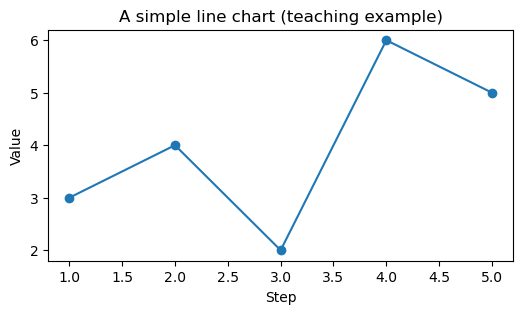

In [17]:
x = [1, 2, 3, 4, 5]
y = [3, 4, 2, 6, 5]
fig, ax = plt.subplots(figsize=(6,3))
ax.plot(x, y, marker="o")
ax.set(title="A simple line chart (teaching example)", xlabel="Step", ylabel="Value")
plt.show()

## 15. Real bar chart: order status

Bar charts compare group sizes. Labels are category names, not numerical intervals.

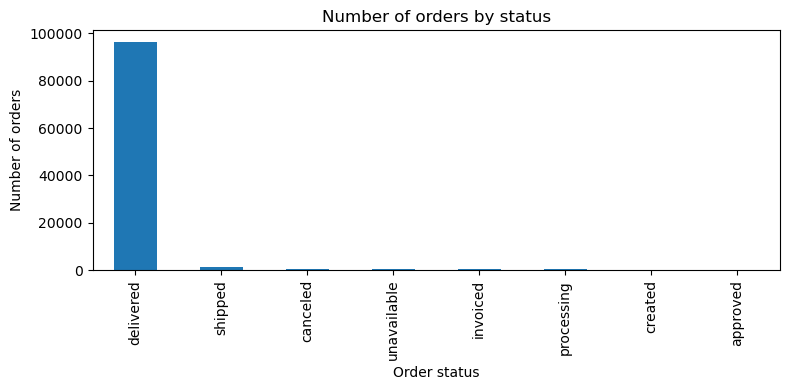

In [18]:
counts = orders["order_status"].value_counts()
ax = counts.plot.bar(figsize=(8,4), title="Number of orders by status")
ax.set(xlabel="Order status", ylabel="Number of orders")
plt.tight_layout(); plt.show()

## 16. Histogram: distribution of item prices

A histogram counts values within numeric bins. Long right tails are common in prices.

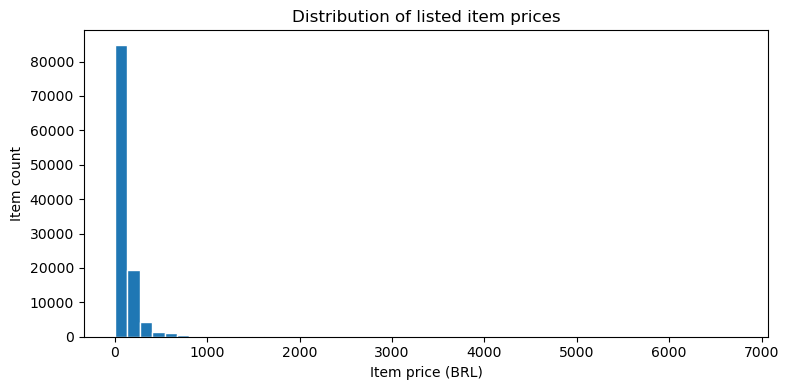

In [19]:
fig, ax = price_histogram(items, bins=50)
plt.show()

## 17. Boxplot and outliers

A boxplot summarizes median, quartiles and unusually distant observations. Displaying a separate zoomed chart may help.

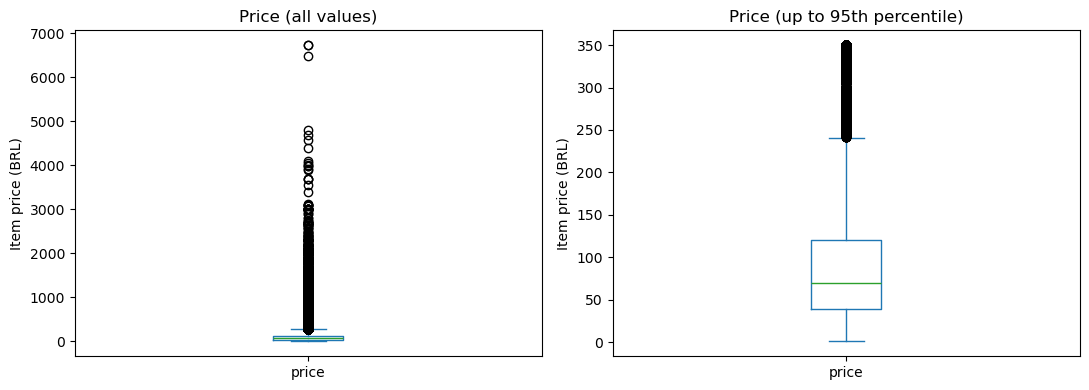

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
items["price"].plot.box(ax=axes[0], title="Price (all values)")
items.loc[items["price"] <= items["price"].quantile(.95), "price"].plot.box(ax=axes[1], title="Price (up to 95th percentile)")
for ax in axes: ax.set_ylabel("Item price (BRL)")
plt.tight_layout(); plt.show()

## 18. Scatter plot: price vs freight

A scatter plot displays relationships between two numeric variables. Sample for speed; association is not causation.

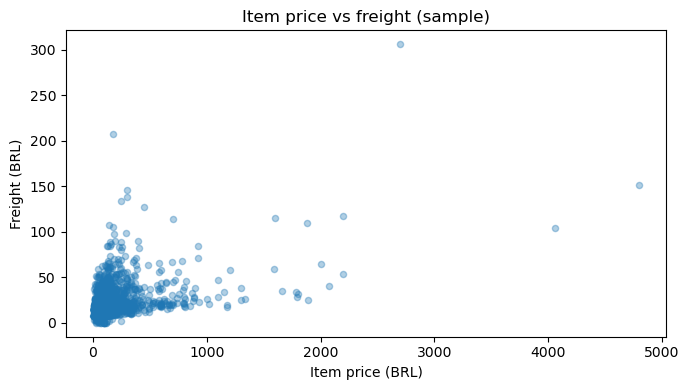

In [21]:
sample = items.sample(n=min(3000, len(items)), random_state=42)
ax = sample.plot.scatter(x="price", y="freight_value", alpha=.35, figsize=(7,4), title="Item price vs freight (sample)")
ax.set(xlabel="Item price (BRL)", ylabel="Freight (BRL)")
plt.tight_layout(); plt.show()

## 19. GroupBy: summarize sellers

`groupby` splits data by a key. `agg` computes several measures for each seller.

In [22]:
sellers = seller_summary(items)
display(sellers.head(10))

,item_count,observed_item_value,average_item_price
seller_id,,,
4869f7a5dfa277a7dca6462dcf3b52b2,1156,229472.63,198.505735
53243585a1d6dc2643021fd1853d8905,410,222776.05,543.356220
4a3ca9315b744ce9f8e9374361493884,1987,200472.92,100.892260
fa1c13f2614d7b5c4749cbc52fecda94,586,194042.03,331.129744
7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,137.774113
7e93a43ef30c4f03f38b393420bc753a,340,176431.87,518.917265
da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,103.311779
7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,121.046567
1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,97.316912


## 20. Horizontal bar chart: top sellers

Always state what you mean by value. Here it is the **sum of observed item prices** (not net revenue).

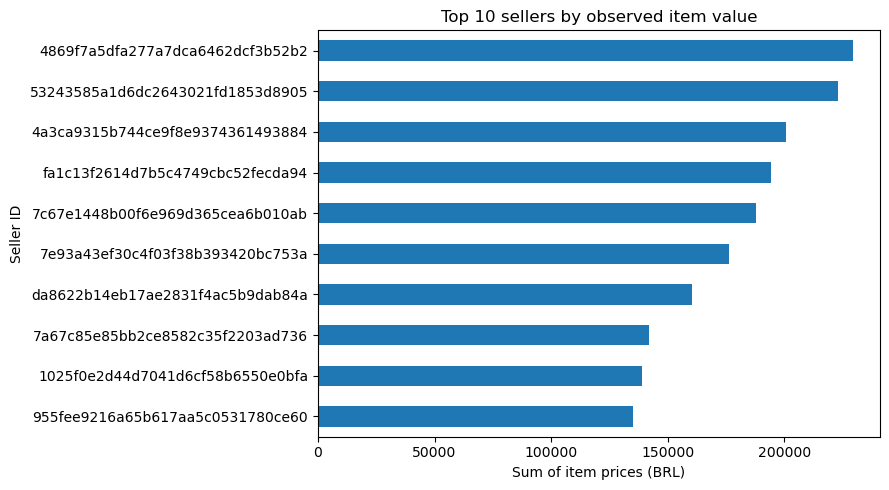

In [23]:
top = sellers.head(10).sort_values("observed_item_value")
ax = top["observed_item_value"].plot.barh(figsize=(9,5), title="Top 10 sellers by observed item value")
ax.set(xlabel="Sum of item prices (BRL)", ylabel="Seller ID")
plt.tight_layout(); plt.show()

## 21. Merge: combine related tables safely

Use `validate="many_to_one"` when joining many items to a single order row. Joining raw payment records here would multiply some item rows.

In [24]:
joined = items.merge(orders[["order_id", "order_status", "order_purchase_timestamp"]], on="order_id", how="left", validate="many_to_one")
assert len(joined) == len(items)
display(joined.head(3))

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_status,order_purchase_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,delivered,2017-09-13 08:59:02
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,delivered,2017-04-26 10:53:06
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,delivered,2018-01-14 14:33:31


## 22. Aggregate to order level before payments

Several line items and several payment records may belong to the same order. Aggregate each separately before joining.

In [25]:
order_items = order_level_items(items)
order_payments = tables["payments"].groupby("order_id", as_index=False).agg(payment_total=("payment_value", "sum"), payment_records=("payment_value", "size"))
order_view = order_items.merge(order_payments, on="order_id", how="left", validate="one_to_one")
print("One row per order:", order_view["order_id"].is_unique)
display(order_view.head())

One row per order: True


,order_id,item_value,freight_total,item_count,payment_total,payment_records
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,72.19,1.0
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,259.83,1.0
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,216.87,1.0
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,25.78,1.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,218.04,1.0


## 23. Category analysis with two joins

Products and translations are lookup tables; group after merging them with item rows.

In [26]:
categories = category_summary(items, tables["products"], tables["translations"])
display(categories.head(10))

,observed_item_value,item_count
product_category_name_english,,
health_beauty,1258681.34,9670
watches_gifts,1205005.68,5991
bed_bath_table,1036988.68,11115
sports_leisure,988048.97,8641
computers_accessories,911954.32,7827
furniture_decor,729762.49,8334
cool_stuff,635290.85,3796
housewares,632248.66,6964
auto,592720.11,4235


## 24. Bar chart: product categories

Show the highest categories by item-price sum.

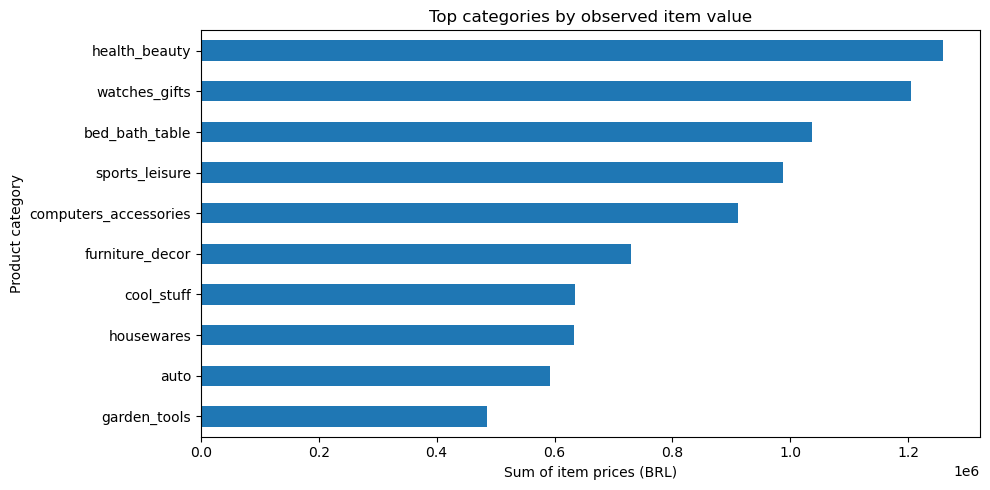

In [27]:
top_categories = categories.head(10).sort_values("observed_item_value")
ax = top_categories["observed_item_value"].plot.barh(figsize=(10,5), title="Top categories by observed item value")
ax.set(xlabel="Sum of item prices (BRL)", ylabel="Product category")
plt.tight_layout(); plt.show()

## 25. Working with dates

Create a purchase month from a datetime. `Period[M]` is suitable for monthly grouping.

In [28]:
orders = orders.copy()
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.to_period("M")
display(orders[["order_purchase_timestamp", "purchase_month"]].head())

,order_purchase_timestamp,purchase_month
0,2017-10-02 10:56:33,2017-10
1,2018-07-24 20:41:37,2018-07
2,2018-08-08 08:38:49,2018-08
3,2017-11-18 19:28:06,2017-11
4,2018-02-13 21:18:39,2018-02


## 26. Monthly line chart

Interpret the ends of the time range cautiously because coverage is not complete in all months.

order_purchase_timestamp
2016-09       134.97
2016-10     40325.11
2016-12        10.90
2017-01    111798.36
2017-02    234223.40
Freq: M, Name: observed_item_value, dtype: float64

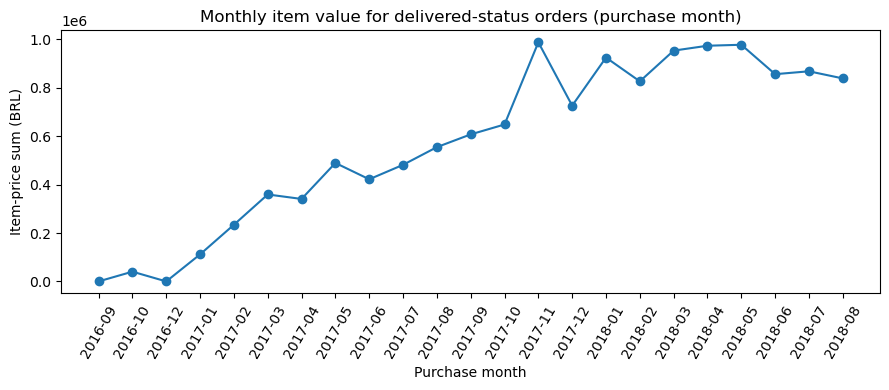

In [29]:
monthly = monthly_item_values(items, orders, delivered_only=True)
display(monthly.head())
fig, ax = monthly_line(monthly)
ax.set_title("Monthly item value for delivered-status orders (purchase month)")
plt.show()

## 27. Rolling average

A three-month rolling mean smooths short-term variation; it does not forecast.

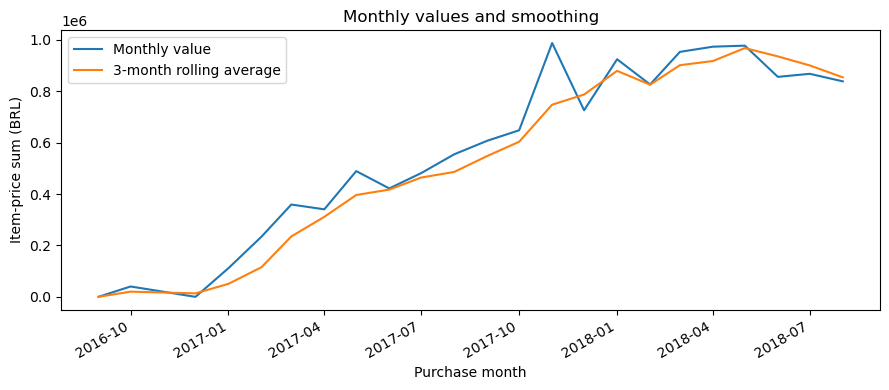

In [30]:
monthly_series = monthly.copy()
monthly_series.index = monthly_series.index.to_timestamp()
ax = monthly_series.plot(figsize=(9,4), label="Monthly value")
monthly_series.rolling(3, min_periods=1).mean().plot(ax=ax, label="3-month rolling average")
ax.set(xlabel="Purchase month", ylabel="Item-price sum (BRL)", title="Monthly values and smoothing")
ax.legend(); plt.tight_layout(); plt.show()

## 28. Month-over-month change

`pct_change()` measures relative change from one month to the next. Exclude incomplete edge months when interpreting patterns.

In [31]:
monthly_change = monthly.pct_change().mul(100)
display(monthly_change.rename("month_over_month_pct").head(12))

order_purchase_timestamp
2016-09             NaN
2016-10    2.977709e+04
2016-12   -9.997297e+01
2017-01    1.025573e+06
2017-02    1.095052e+02
2017-03    5.335737e+01
2017-04   -5.158471e+00
2017-05    4.364009e+01
2017-06   -1.377674e+01
2017-07    1.414502e+01
2017-08    1.517743e+01
2017-09    9.500631e+00
Freq: M, Name: month_over_month_pct, dtype: float64

## 29. Pivot tables

A pivot table reorganizes grouped values into a matrix.

In [32]:
status_by_year = pd.crosstab(orders["order_purchase_timestamp"].dt.year, orders["order_status"])
display(status_by_year)

order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable
order_purchase_timestamp,,,,,,,,
2016,0,26,0,267,18,2,9,7
2017,2,265,4,43428,175,240,530,457
2018,0,334,1,52783,121,59,568,145


## 30. Stacked bar charts

Stacked bars compare absolute counts and their composition.

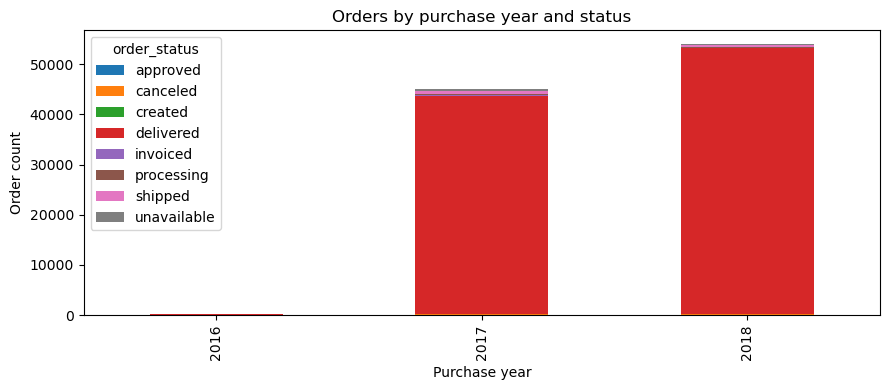

In [33]:
ax = status_by_year.plot.bar(stacked=True, figsize=(9,4), title="Orders by purchase year and status")
ax.set(xlabel="Purchase year", ylabel="Order count")
plt.tight_layout(); plt.show()

## 31. Correlation and heatmaps

Correlations measure linear association; relationships can be non-linear. Never interpret correlation as proof of cause.

,price,freight_value,order_item_id
price,1.000000,0.414204,-0.060522
freight_value,0.414204,1.000000,-0.029380
order_item_id,-0.060522,-0.029380,1.000000


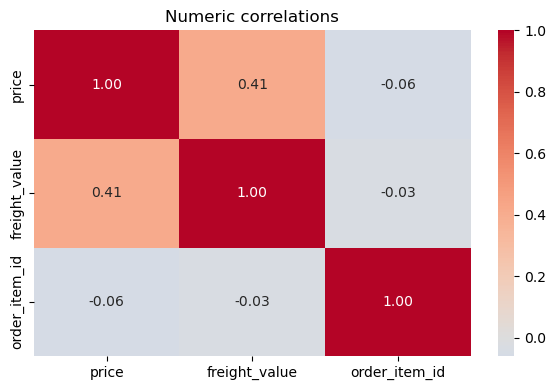

In [34]:
numeric = items[["price", "freight_value", "order_item_id"]]
correlation = numeric.corr()
display(correlation)
fig, ax=plt.subplots(figsize=(6,4))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Numeric correlations")
plt.tight_layout(); plt.show()

## 32. KDE: smooth distribution

A kernel density estimate smooths a continuous distribution. Restrict the plotted range only for readability, and label this explicitly.

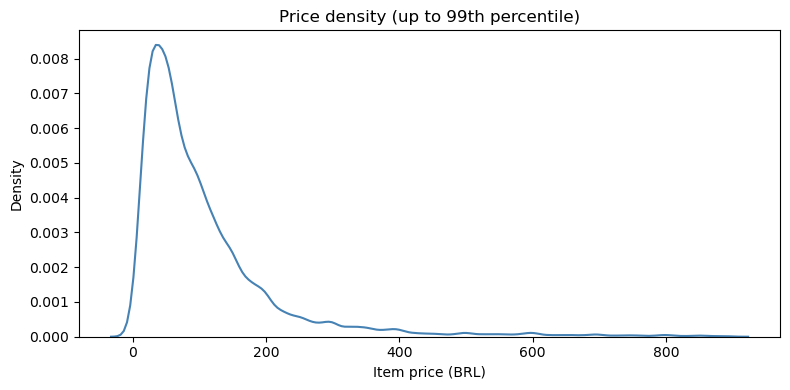

In [35]:
cutoff=items["price"].quantile(.99)
subset=items.loc[items["price"] <= cutoff, "price"]
fig,ax=plt.subplots(figsize=(8,4))
sns.kdeplot(x=subset, ax=ax, color="steelblue")
ax.set(title="Price density (up to 99th percentile)", xlabel="Item price (BRL)")
plt.tight_layout();plt.show()

## 33. Advanced grouping: transform

`transform` returns one result per original row, letting you compare each item to its seller mean.

In [36]:
working=items[["seller_id", "price"]].copy()
working["seller_mean_price"] = working.groupby("seller_id")["price"].transform("mean")
working["difference_from_seller_mean"] = working["price"] - working["seller_mean_price"]
display(working.head())

,seller_id,price,seller_mean_price,difference_from_seller_mean
0,48436dade18ac8b2bce089ec2a041202,58.90,81.269603,-22.369603
1,dd7ddc04e1b6c2c614352b383efe2d36,239.90,64.185385,175.714615
2,5b51032eddd242adc84c38acab88f23d,199.00,234.285714,-35.285714
3,9d7a1d34a5052409006425275ba1c2b4,12.99,65.926250,-52.936250
4,df560393f3a51e74553ab94004ba5c87,199.90,126.247586,73.652414


## 34. Ranking and quantile groups

Use `rank()` to order sellers and `qcut()` to split a numeric range into quantile bands.

In [37]:
seller_rank=sellers.copy()
seller_rank["value_rank"]=seller_rank["observed_item_value"].rank(ascending=False, method="dense")
items_band=items[["price"]].copy()
items_band["price_quartile"]=pd.qcut(items_band["price"], q=4, labels=["Q1","Q2","Q3","Q4"], duplicates="drop")
display(items_band["price_quartile"].value_counts().sort_index())

price_quartile
Q1    28501
Q2    27940
Q3    28095
Q4    28114
Name: count, dtype: int64

## 35. Delivery times

For delivered orders with both actual and estimated dates, define a delay in days. Null dates must not be assumed on-time.

In [38]:
delivered=orders.loc[orders["order_status"].eq("delivered")].copy()
delivered=delivered.dropna(subset=["order_delivered_customer_date","order_estimated_delivery_date"])
delivered["delay_days"]=(delivered["order_delivered_customer_date"] - delivered["order_estimated_delivery_date"]).dt.total_seconds()/86400
delivered["late"] = delivered["delay_days"] > 0
print("Late-delivery share:", round(delivered["late"].mean()*100,2), "%")

Late-delivery share: 8.11 %


## 36. Review scores and delivery timing

Aggregate potentially multiple review rows to one score per order before joining to avoid duplicating deliveries.

In [39]:
reviews_per_order=tables["reviews"].groupby("order_id",as_index=False).agg(mean_review_score=("review_score","mean"))
delivery_review=delivered[["order_id","late"]].merge(reviews_per_order,on="order_id",how="left",validate="one_to_one")
display(delivery_review.groupby("late")["mean_review_score"].agg(["count","mean","median"]))

,count,mean,median
late,,,
False,88163,4.294292,5.0
True,7661,2.566506,2.0


## 37. Review score bar chart

Show observed mean review scores by delivery group. Association does not demonstrate causality.

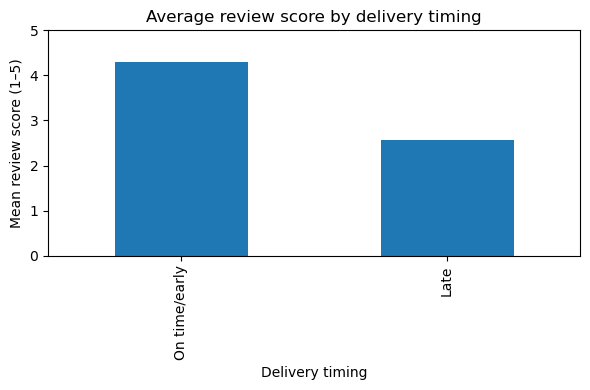

In [40]:
avg_review=delivery_review.groupby("late")["mean_review_score"].mean()
ax=avg_review.rename(index={False:"On time/early",True:"Late"}).plot.bar(figsize=(6,4),title="Average review score by delivery timing")
ax.set(xlabel="Delivery timing",ylabel="Mean review score (1–5)",ylim=(0,5))
plt.tight_layout();plt.show()

## 38. Payment method distributions

Count payment records here, not distinct orders; orders can have several payment records.

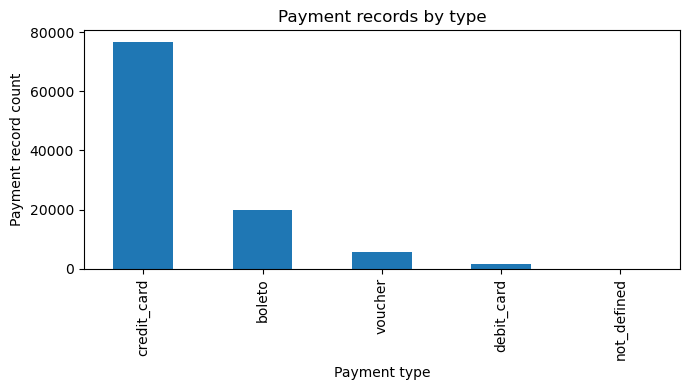

In [41]:
payment_counts=tables["payments"]["payment_type"].value_counts()
ax=payment_counts.plot.bar(figsize=(7,4),title="Payment records by type")
ax.set(xlabel="Payment type",ylabel="Payment record count")
plt.tight_layout();plt.show()

## 39. Customer geography

Customer table has one row per order-customer record. State counts are counts of customer records, not necessarily unique people.

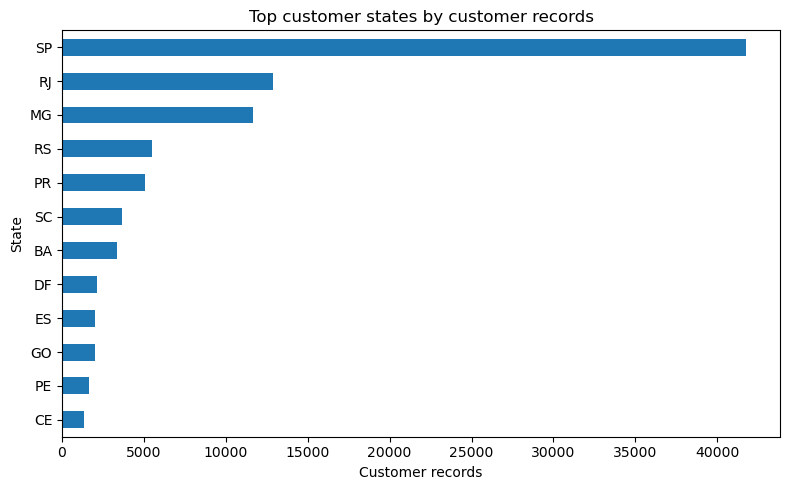

In [42]:
state_counts=tables["customers"]["customer_state"].value_counts().head(12)
ax=state_counts.sort_values().plot.barh(figsize=(8,5),title="Top customer states by customer records")
ax.set(xlabel="Customer records",ylabel="State")
plt.tight_layout();plt.show()

## 40. Unique customers vs orders

`customer_unique_id` tracks a person across orders more consistently than `customer_id`.

In [43]:
print("Customer table rows:",len(tables["customers"]))
print("Unique customers:",tables["customers"]["customer_unique_id"].nunique())
repeat=tables["customers"]["customer_unique_id"].value_counts()
print("Customers appearing multiple times:",(repeat>1).sum())

Customer table rows: 99441
Unique customers: 96096
Customers appearing multiple times: 2997


## 41. Product prices across sellers

Compare products sold by multiple sellers. These are transaction prices observed across the whole time window, **not simultaneous offers**.

In [44]:
spreads=multi_seller_product_spreads(items)
print("Products sold by multiple sellers:",len(spreads))
display(spreads.head(10))

Products sold by multiple sellers: 1225


,distinct_sellers,observations,min_observed_price,max_observed_price,observed_spread_pct
product_id,,,,,
668627d7997bde540866a91f02484ae6,2,2,6.33,49.89,688.151659
d41d8cd98f00b204e9800998ecf8427e,4,13,39.99,259.90,549.912478
d69e906470f99256b16bee14a0268fd1,2,7,17.00,89.90,428.823529
69455f41626a745aea9ee9164cb9eafd,8,41,110.00,337.69,206.990909
500870614ddcf5bd84f7d26861026c8a,3,32,11.87,34.99,194.776748
a695ab8413ea83619cde9b18292d6aa1,2,23,20.99,59.49,183.420677
8ec2aeacda2a58c1e118e8c1ea90c605,2,3,85.00,230.00,170.588235
ad2037645597db38527fe3afbe226af2,2,23,29.49,74.49,152.594100
081476f0ad46b45e23bbd0f3d1d4dd98,2,3,19.90,49.90,150.753769


## 42. Avoid mixing purchase dates

Group observed prices by product, seller and purchase month. Sparse observations still limit comparisons.

In [45]:
monthly_seller_prices=product_month_price_comparison(items,orders)
display(monthly_seller_prices.head())
print("Grouped rows:",len(monthly_seller_prices))

,product_id,purchase_month,seller_id,observations,average_price
0,00066f42aeeb9f3007548bb9d3f33c38,2018-05,5670f4db5b62c43d542e1b2d56b0cf7c,1,101.65
1,00088930e925c41fd95ebfe695fd2655,2017-12,7142540dd4c91e2237acb7e911c4eba2,1,129.90
2,0009406fd7479715e4bef61dd91f2462,2017-12,4a3ca9315b744ce9f8e9374361493884,1,229.00
3,000b8f95fcb9e0096488278317764d19,2018-08,40ec8ab6cdafbcc4f544da38c67da39a,2,58.90
4,000d9be29b5207b54e86aa1b1ac54872,2018-04,8ae520247981aa06bc94abddf5f46d34,1,199.00


Grouped rows: 62672


## 43. Advanced distribution: observed price spreads

Extreme values may arise from price changes, product variants not captured in IDs, or sparse observations; do not infer coordinated pricing.

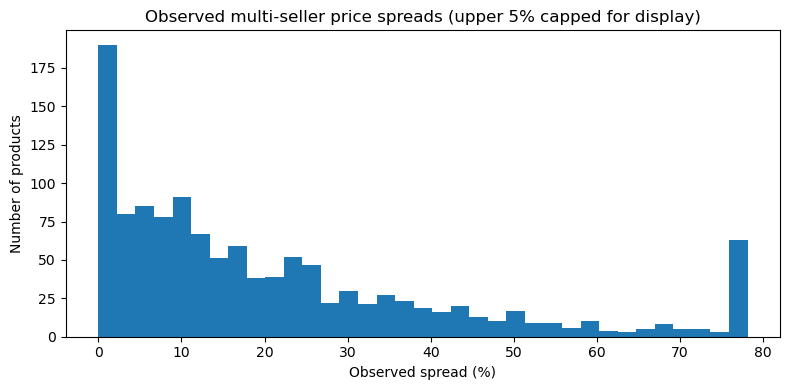

In [46]:
plot_spreads=spreads["observed_spread_pct"].clip(upper=spreads["observed_spread_pct"].quantile(.95))
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(plot_spreads,bins=35)
ax.set(title="Observed multi-seller price spreads (upper 5% capped for display)",xlabel="Observed spread (%)",ylabel="Number of products")
plt.tight_layout();plt.show()

## 44. Pair plot for multiple features

Seaborn pairplot illustrates several numeric distributions and relationships; use a sample for performance.

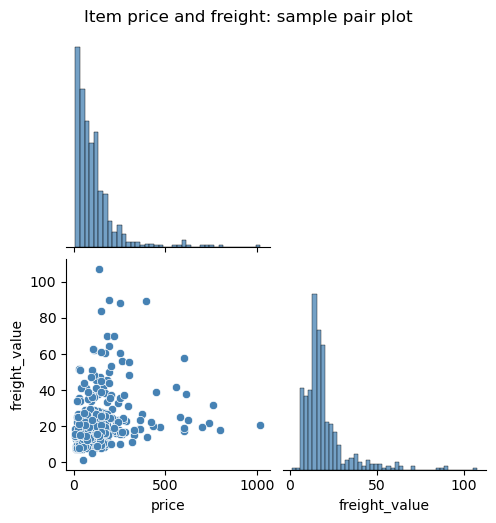

In [47]:
small = items[["price","freight_value"]].sample(n=500, random_state=42)
g=sns.pairplot(small, corner=True, plot_kws={"color": "steelblue"}, diag_kws={"color": "steelblue"})
g.fig.suptitle("Item price and freight: sample pair plot",y=1.03)
plt.show()

## 45. Export clean reports and a figure

Write reproducible output into `results/` and `figures/` (both folders are already provided). Avoid uploading large generated files unless helpful.

In [48]:
(PROJECT_ROOT/"results").mkdir(exist_ok=True)
(PROJECT_ROOT/"figures").mkdir(exist_ok=True)
sellers.head(20).to_csv(PROJECT_ROOT/"results"/"top_20_sellers.csv")
fig,ax=price_histogram(items)
fig.savefig(PROJECT_ROOT/"figures"/"price_distribution.png",dpi=160,bbox_inches="tight")
plt.close(fig)
print("Reports saved in results/ and figures/")

Reports saved in results/ and figures/


## 46. Exercises: beginner to advanced

**Try independently:** (1) show five largest prices; (2) count cancelled orders; (3) find median freight; (4) plot the top five payment types; (5) group item value by seller; (6) identify multi-seller products whose prices varied within the same purchase month. Think about sample sizes and missing dates. Suggested answer snippets appear below.

In [49]:
# Beginner examples
print(items.nlargest(5,"price")[["price","product_id"]])
print((orders["order_status"] == "canceled").sum())
print(items["freight_value"].median())

# Advanced exercise scaffold: count distinct sellers per product-month
multi_seller_months=(monthly_seller_prices.groupby(["product_id","purchase_month"])["seller_id"]
                     .nunique().loc[lambda s:s>1])
print("Product-month combinations with multiple sellers:",len(multi_seller_months))

         price                        product_id
3556    6735.0  489ae2aa008f021502940f251d4cce7f
112233  6729.0  69c590f7ffc7bf8db97190b6cb6ed62e
107841  6499.0  1bdf5e6731585cf01aa8169c7028d6ad
74336   4799.0  a6492cc69376c469ab6f61d8f44de961
11249   4690.0  c3ed642d592594bb648ff4a04cee2747
625
16.26
Product-month combinations with multiple sellers: 445


## 47. Final interpretation and research caveats

You can now explain: how data is shaped; how to clean and merge it; what summary charts show; and how to avoid double counting. **Important:** observed item prices are not true inventory-wide posted prices, status does not confirm payment settlement, and descriptive differences alone cannot establish causal effects or algorithmic collusion. Review the README before publishing.